# Bài 6: Máy vectơ hỗ trợ (SVM) – Thực hành trên dữ liệu sinh viên

## 0. Nạp thư viện và dữ liệu

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

plt.rcParams["figure.dpi"] = 100

In [2]:
import os
CAN = ["sinh_vien.csv", "sinh_vien_mo_rong.csv"]
thieu = [f for f in CAN if not os.path.exists(f)]
if thieu:
    try:
        from google.colab import files
        print("Hay chon cac tep:", thieu)
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"Khong tim thay {thieu}, hay dat vao cung thu muc voi notebook")

df2 = pd.read_csv("sinh_vien.csv")            # 2 cot dac trung
df3 = pd.read_csv("sinh_vien_mo_rong.csv")    # 3 cot dac trung
print(df2.shape, df3.shape)
df3.head()

(120, 3) (120, 4)


,gio_on,diem_giua_ky,chi_tieu,qua_mon
0,5.5,3.0,5050,0
1,19.0,6.0,7700,1
2,14.0,7.7,2850,0
3,11.0,3.1,7700,0
4,10.5,5.8,3850,1


In [3]:
# Nhìn qua dữ liệu trước khi học
print(df3.describe().round(2))
print()
print("Ti le qua mon:", df2["qua_mon"].mean())

       gio_on  diem_giua_ky  chi_tieu  qua_mon
count  120.00        120.00    120.00   120.00
mean    15.15          5.50   5054.58     0.59
std      7.85          2.10   1698.76     0.49
min      0.00          0.30   2050.00     0.00
25%      9.38          4.12   3550.00     0.00
50%     15.50          5.70   5050.00     1.00
75%     20.12          7.00   6600.00     1.00
max     29.50         10.00   8000.00     1.00

Ti le qua mon: 0.5916666666666667


In [4]:
X = df2[["gio_on", "diem_giua_ky"]]
y = df2["qua_mon"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

print("Tap hoc co", len(X_tr), "ban")
print("      C  so vecto HT  do rong le  tap hoc  tap kiem tra")
for C in [0.01, 0.1, 1, 10, 100]:
    mh = make_pipeline(StandardScaler(), SVC(kernel="linear", C=C))
    mh.fit(X_tr, y_tr)
    svm = mh[-1]                      # buoc cuoi cua pipeline la SVM
    le = 2 / np.linalg.norm(svm.coef_[0])
    a_hoc = accuracy_score(y_tr, mh.predict(X_tr))
    a_kt = accuracy_score(y_te, mh.predict(X_te))
    print(f" {C:6} {len(svm.support_):10d} {le:11.2f} {a_hoc:8.4f} {a_kt:13.4f}")

Tap hoc co 90 ban
      C  so vecto HT  do rong le  tap hoc  tap kiem tra
   0.01         74        3.84   0.8556        0.8667
    0.1         44        1.70   0.8889        0.9000
      1         31        1.29   0.8778        0.9000
     10         28        1.06   0.9000        0.9000
    100         27        1.05   0.9000        0.9000


**Vẽ ranh giới và vectơ hỗ trợ** với `C = 0.01` và `C = 100` (vectơ hỗ trợ được khoanh vàng).

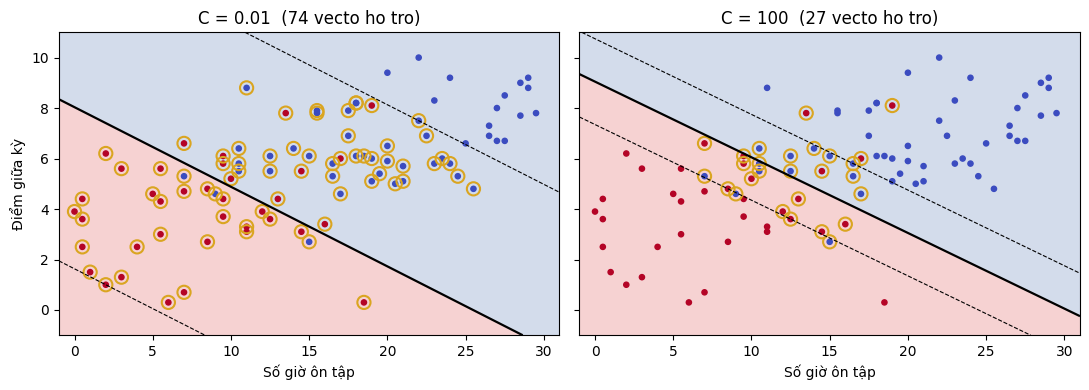

In [5]:
def ve_ranh_gioi(C, ax):
    mh = make_pipeline(StandardScaler(), SVC(kernel="linear", C=C)).fit(X_tr, y_tr)
    xx, yy = np.meshgrid(np.linspace(-1, 31, 300), np.linspace(-1, 11, 300))
    luoi = pd.DataFrame({"gio_on": xx.ravel(), "diem_giua_ky": yy.ravel()})
    f = mh.decision_function(luoi).reshape(xx.shape)
    ax.contourf(xx, yy, f, levels=[-100, 0, 100], colors=["#f4c7c7", "#c9d4e6"], alpha=0.8)
    ax.contour(xx, yy, f, levels=[-1, 0, 1], colors="k",
               linestyles=["--", "-", "--"], linewidths=[0.8, 1.6, 0.8])
    ax.scatter(X_tr["gio_on"], X_tr["diem_giua_ky"], c=y_tr, cmap="coolwarm_r", s=14)
    sv = mh[-1].support_
    ax.scatter(X_tr.iloc[sv, 0], X_tr.iloc[sv, 1], s=90, facecolors="none",
               edgecolors="goldenrod", linewidths=1.5)
    ax.set_title(f"C = {C}  ({len(sv)} vecto ho tro)")
    ax.set_xlabel("Số giờ ôn tập")

fig, axs = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
ve_ranh_gioi(0.01, axs[0]); ve_ranh_gioi(100, axs[1])
axs[0].set_ylabel("Điểm giữa kỳ")
plt.tight_layout(); plt.show()

In [6]:
X3 = df3[["gio_on", "diem_giua_ky", "chi_tieu"]]
y3 = df3["qua_mon"]
X3_tr, X3_te, y3_tr, y3_te = train_test_split(
    X3, y3, test_size=0.25, random_state=17, stratify=y3
)

print("Do lech chuan tung cot:")
print(X3_tr.std().round(2).to_string())
print()

tho = SVC().fit(X3_tr, y3_tr)
chuan = make_pipeline(StandardScaler(), SVC()).fit(X3_tr, y3_tr)
print("Ba cot, kernel RBF mac dinh")
print(f"  Doan bua ca lop qua : {y3_te.mean():.4f}")
print(f"  Khong chuan hoa     : {accuracy_score(y3_te, tho.predict(X3_te)):.4f}")
print(f"  Co chuan hoa        : {accuracy_score(y3_te, chuan.predict(X3_te)):.4f}")

Do lech chuan tung cot:
gio_on             8.13
diem_giua_ky       2.16
chi_tieu        1720.71

Ba cot, kernel RBF mac dinh
  Doan bua ca lop qua : 0.6000
  Khong chuan hoa     : 0.6000
  Co chuan hoa        : 0.9000


In [7]:
print("gamma  tap hoc  tap kiem tra  so vecto HT")
for g in [0.01, 0.1, 1, 10, 100]:
    mh = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1, gamma=g)).fit(X3_tr, y3_tr)
    a_hoc = accuracy_score(y3_tr, mh.predict(X3_tr))
    a_kt = accuracy_score(y3_te, mh.predict(X3_te))
    print(f"{g:6} {a_hoc:8.4f} {a_kt:13.4f} {len(mh[-1].support_):11d}")

gamma  tap hoc  tap kiem tra  so vecto HT
  0.01   0.8556        0.8667          63
   0.1   0.8889        0.9000          41
     1   0.9111        0.9000          54
    10   1.0000        0.7000          89
   100   1.0000        0.6000          90


In [8]:
# Do luoi: thu moi cap (C, gamma) bang kiem dinh cheo 5 phan, chi tren tap hoc
pipe = make_pipeline(StandardScaler(), SVC(kernel="rbf"))
luoi = {"svc__C": [0.1, 1, 10, 100], "svc__gamma": [0.001, 0.01, 0.1, 1]}
tim = GridSearchCV(pipe, luoi, cv=5)
tim.fit(X3_tr, y3_tr)

bang = pd.DataFrame(tim.cv_results_["params"])
bang["diem"] = tim.cv_results_["mean_test_score"]
print("Diem kiem dinh cheo (hang la C, cot la gamma)")
print(bang.pivot(index="svc__C", columns="svc__gamma", values="diem").round(4).to_string())
print()
print("Cap tot nhat:", tim.best_params_)
print(f"Diem kiem dinh cheo: {tim.best_score_:.4f}")
print(f"Accuracy tren tap kiem tra: {tim.score(X3_te, y3_te):.4f}")

Diem kiem dinh cheo (hang la C, cot la gamma)
svc__gamma   0.001   0.010   0.100   1.000
svc__C                                    
0.1         0.5889  0.5889  0.7889  0.5889
1.0         0.5889  0.8556  0.8889  0.8889
10.0        0.8556  0.8889  0.8889  0.8333
100.0       0.8889  0.8889  0.8667  0.7778

Cap tot nhat: {'svc__C': 1, 'svc__gamma': 0.1}
Diem kiem dinh cheo: 0.8889
Accuracy tren tap kiem tra: 0.9000


---
# Bài tập
Nộp: mã nguồn (notebook) và ảnh chụp phần kết quả. Mỗi bài có một ô code khung, hãy tự viết trước khi xem gợi ý. Bài 1 và bài 5 chấm nặng phần giải thích bằng lời.

## Bài tập 1: Tính tay khoảng cách tới ranh giới


In [9]:
mh1 = make_pipeline(StandardScaler(), SVC(kernel="linear", C=1)).fit(X_tr, y_tr)
scaler, svm1 = mh1[0], mh1[-1]
w = svm1.coef_[0]; b = svm1.intercept_[0]
print(f"w1 = {w[0]:.3f}, w2 = {w[1]:.3f}, b = {b:.3f}")
do_dai_w = np.sqrt(w[0]**2 + w[1]**2)
print("Do rong le =", round(2 / do_dai_w, 3))

# --- b) va c) ---
hai_ban = X_te.iloc[:2].to_numpy()
z = (hai_ban - scaler.mean_) / scaler.scale_       # chuan hoa tay
f_tay = z[:, 0] * w[0] + z[:, 1] * w[1] + b
f_thu_vien = mh1.decision_function(X_te.iloc[:2])
print("f tay      :", f_tay.round(4))
print("f thu vien :", f_thu_vien.round(4))
print("Khoang cach:", (np.abs(f_tay) / do_dai_w).round(4))

# --- d) cac vecto ho tro nam dung tren mep le ---
f_sv = mh1.decision_function(X_tr.iloc[svm1.support_])
tren_mep = np.isclose(np.abs(f_sv), 1, atol=1e-3)
print("So vecto HT:", len(f_sv), "- so diem nam dung tren mep le:", tren_mep.sum())
print("Khoang cach cua chung:", (1 / do_dai_w).round(4), "= mot nua do rong le", round(1 / do_dai_w, 4))

w1 = 1.294, w2 = 0.858, b = 0.378
Do rong le = 1.288
f tay      : [ 1.6399 -1.4793]
f thu vien : [ 1.6399 -1.4793]
Khoang cach: [1.056  0.9526]
So vecto HT: 31 - so diem nam dung tren mep le: 6
Khoang cach cua chung: 0.6439 = mot nua do rong le 0.6439


**Trả lời (d):** *(viết bằng lời của em)* — gợi ý: trên mép lề `|f(x)| = 1`, nên khoảng cách là `1/‖w‖`, còn lề `= 2/‖w‖`.  
Lưu ý: vì dữ liệu không tách sạch nên còn có vectơ hỗ trợ **nằm trong lề hoặc sai phía** (`|f| < 1`), chúng không thuộc nhóm trên.

## Bài tập 2: Chuẩn hoá thủ công so với `StandardScaler`


In [10]:
df3_b = df3.copy()
df3_b["chi_tieu_trieu"] = df3_b["chi_tieu"] / 1000
cot = ["gio_on", "diem_giua_ky", "chi_tieu_trieu"]
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(
    df3_b[cot], df3_b["qua_mon"], test_size=0.25, random_state=17, stratify=df3_b["qua_mon"]
)
mh_b = SVC().fit(Xb_tr, yb_tr)
print("Doi sang trieu, khong chuan hoa:", round(accuracy_score(yb_te, mh_b.predict(Xb_te)), 4))
print("Do lech chuan tung cot:")
print(Xb_tr.std().round(3).to_string())

Doi sang trieu, khong chuan hoa: 0.9
Do lech chuan tung cot:
gio_on            8.133
diem_giua_ky      2.159
chi_tieu_trieu    1.721


## Bài tập 3: Chọn C và gamma trên bộ 3 cột, lưới mịn

In [11]:
# Quanh cap tot nhat o Vi du 3: C = 1, gamma = 0.1
luoi_min = {"svc__C": [0.3, 1, 3], "svc__gamma": [0.03, 0.1, 0.3]}
tim_min = GridSearchCV(make_pipeline(StandardScaler(), SVC()), luoi_min, cv=5).fit(X3_tr, y3_tr)
print("Cap tot nhat:", tim_min.best_params_)
print(f"Kiem dinh cheo (luoi min): {tim_min.best_score_:.4f}  | (luoi thua): {tim.best_score_:.4f}")
print(f"Tap kiem tra   (luoi min): {tim_min.score(X3_te, y3_te):.4f}  | (luoi thua): {tim.score(X3_te, y3_te):.4f}")

Cap tot nhat: {'svc__C': 3, 'svc__gamma': 0.3}
Kiem dinh cheo (luoi min): 0.9000  | (luoi thua): 0.8889
Tap kiem tra   (luoi min): 0.9000  | (luoi thua): 0.9000


## Bài tập 4: Kernel đa thức


In [12]:
ket_qua = []
for d in [2, 3, 4]:
    pipe_p = make_pipeline(StandardScaler(), SVC(kernel="poly", degree=d))
    g = GridSearchCV(pipe_p, {"svc__C": [0.1, 1, 10, 100]}, cv=5).fit(X3_tr, y3_tr)
    ket_qua.append({"bac": d, "C tot nhat": g.best_params_["svc__C"],
                    "kiem dinh cheo": round(g.best_score_, 4),
                    "tap kiem tra": round(g.score(X3_te, y3_te), 4)})
ket_qua.append({"bac": "RBF", "C tot nhat": tim.best_params_["svc__C"],
                "kiem dinh cheo": round(tim.best_score_, 4),
                "tap kiem tra": round(tim.score(X3_te, y3_te), 4)})
pd.DataFrame(ket_qua)

,bac,C tot nhat,kiem dinh cheo,tap kiem tra
0,2,100,0.6333,0.6000
1,3,100,0.8889,0.9000
2,4,1,0.6444,0.5667
3,RBF,1,0.8889,0.9000


## Bài tập 5: Cột nào quan trọng? (SVM tuyến tính trên 3 cột)


In [13]:
mh5 = make_pipeline(StandardScaler(), SVC(kernel="linear", C=1)).fit(X3_tr, y3_tr)
he_so = pd.Series(mh5[-1].coef_[0], index=X3_tr.columns)
print(he_so.round(3).to_string())
print()
print(f"Accuracy tap kiem tra (3 cot, tuyen tinh): {accuracy_score(y3_te, mh5.predict(X3_te)):.4f}")

mh5b = make_pipeline(StandardScaler(), SVC(kernel="linear", C=1)).fit(X3_tr[["gio_on", "diem_giua_ky"]], y3_tr)
print(f"Accuracy tap kiem tra (bo chi_tieu)      : {accuracy_score(y3_te, mh5b.predict(X3_te[['gio_on','diem_giua_ky']])):.4f}")

gio_on          1.281
diem_giua_ky    0.923
chi_tieu       -0.163

Accuracy tap kiem tra (3 cot, tuyen tinh): 0.9000
Accuracy tap kiem tra (bo chi_tieu)      : 0.9000
